In [1]:
import ROOT
import pandas as pd
import numpy as np
import os
import sys
import ipynbname
from pathlib import Path

project_root = str(ipynbname.path().parent.parent)
sys.path.append(project_root)
project_root=Path(project_root)

from processing import SiphraAcquisition, MetadataLoader, MatchedSiphraAcquisition, match_events
from analysis import fit_peak_expbg

# Constants
BITS12 = 2**12
BITS9 = 2**9 # 512 typical number of bins used

# Energy emission peaks in MeV
K40_MEV = [1.460]
TL208_MEV = [2.614]
CS137_MEV = [0.661]
ANNIHIL_MEV = 0.511
NA22_MEV = [ANNIHIL_MEV, 1.2745, 1.2745+ANNIHIL_MEV]
CO60_MEV = [(1.1732+1.3325)/2, 1.1732+1.3325] # First value is the average of the two photopeaks. They have the same branching ratio

colors = [
    ROOT.kRed,
    ROOT.kBlue,
    ROOT.kGreen + 2,
    ROOT.kOrange + 7,
    ROOT.kMagenta,
    ROOT.kCyan + 2,
    ROOT.kViolet,
    ROOT.kAzure + 7,
    ROOT.kPink + 7,
    ROOT.kTeal + 3,
    ROOT.kSpring + 5,
    ROOT.kYellow + 2,
    ROOT.kOrange + 1,
    ROOT.kBlue - 7,
    ROOT.kRed - 7,
    ROOT.kGray + 2,
    ROOT.kBlack,
    ROOT.kSpring - 7
]

In [2]:
siphras = ['A', 'B']
#siphras = ['A']

acqs = {}

files_A = sorted((project_root / 'data/261019').glob('SUBT_A_0[1-8]*.csv'))
files_A_sum = [f for f in files_A if 'Sum' in f.name]
files_A_16  = [f for f in files_A if '16' in f.name]


files_B = sorted((project_root / 'data/261019').glob('SUBT_B_0[1-8]*.csv'))
files_B_sum = [f for f in files_B if 'Sum' in f.name]
files_B_16  = [f for f in files_B if '16' in f.name]


#acqs_A = [SiphraAcquisition(file) for file in files_A]
#acqs_B = [SiphraAcquisition(file) for file in files_B]

acqs_A_sum = [SiphraAcquisition(file) for file in files_A_sum]
acqs_A_16 = [SiphraAcquisition(file) for file in files_A_16]

acqs_B_sum = [SiphraAcquisition(file) for file in files_A_sum]
acqs_B_16 = [SiphraAcquisition(file) for file in files_A_16]

acqs['A'] = {"sum_ch": acqs_A_sum, "all_ch": acqs_A_16}
acqs['B'] = {"sum_ch": acqs_B_sum, "all_ch": acqs_A_16}


#acqs_AB = [acqs_A, acqs_B]

print(acqs)

{'A': {'sum_ch': [SIPHRAAcquisition(File: 'SUBT_A_01_SumChTrigger_BG'), SIPHRAAcquisition(File: 'SUBT_A_02_SumChTrigger_Cs137'), SIPHRAAcquisition(File: 'SUBT_A_07_SumChTrigger_Na22'), SIPHRAAcquisition(File: 'SUBT_A_08_SumChTrigger_Co60')], 'all_ch': [SIPHRAAcquisition(File: 'SUBT_A_03_16ChTrigger_BG'), SIPHRAAcquisition(File: 'SUBT_A_04_16ChTrigger_Cs137'), SIPHRAAcquisition(File: 'SUBT_A_05_16ChTrigger_Co60'), SIPHRAAcquisition(File: 'SUBT_A_06_16ChTrigger_Na22')]}, 'B': {'sum_ch': [SIPHRAAcquisition(File: 'SUBT_A_01_SumChTrigger_BG'), SIPHRAAcquisition(File: 'SUBT_A_02_SumChTrigger_Cs137'), SIPHRAAcquisition(File: 'SUBT_A_07_SumChTrigger_Na22'), SIPHRAAcquisition(File: 'SUBT_A_08_SumChTrigger_Co60')], 'all_ch': [SIPHRAAcquisition(File: 'SUBT_A_03_16ChTrigger_BG'), SIPHRAAcquisition(File: 'SUBT_A_04_16ChTrigger_Cs137'), SIPHRAAcquisition(File: 'SUBT_A_05_16ChTrigger_Co60'), SIPHRAAcquisition(File: 'SUBT_A_06_16ChTrigger_Na22')]}}


In [3]:
print(acqs['A']["sum_ch"][3].source)

Co-60


In [4]:
# Create histograms
hists = {}
triggers = ["sum_ch", "all_ch"]
sources = ["Cs-137", "Co-60", "Na-22"]

for siphra in siphras:
    print(siphra)
    acq_siphra = acqs[siphra]

    for trigger in (triggers):
        print(trigger)
        acq_trig = acq_siphra[trigger]

        bg = acq_trig[0]
        hist_bg = ROOT.TH1F(f"{trigger}_trigger_SIPHRA_{siphra}_BG", "", BITS12, 0, BITS12)
        hist_bg.Fill(bg['Manual_sum']/16)

        hists[f"{trigger}_trigger_SIPHRA_{siphra}_BG"] = hist_bg
        
        for acq in acq_trig:
            source = acq.source
            
            if source != 'BG':
                print(source)
                hist_sgnl = ROOT.TH1F(f"{trigger}_trigger_SIPHRA_{siphra}_{source}_signal", "", BITS12, 0, BITS12)
                
                hist_sgnl.Fill(acq['Manual_sum']/16)
                hist_sgnl.Scale(bg.exposure/acq.exposure)

                hist_clean = hist_sgnl.Clone(f"{trigger}_trigger_SIPHRA_{siphra}_clean")
                hist_clean.Add(hist_bg, -1)

                for hist in [hist_sgnl, hist_clean]:
                    hist.SetTitle(r"Title")
                    hist.GetXaxis().SetTitle(r"ADC channel number")
                    hist.GetYaxis().SetTitle(r"Normalized counts")
            
                hists[f"{trigger}_trigger_SIPHRA_{siphra}_{source}_signal"] = hist_sgnl
                hists[f"{trigger}_trigger_SIPHRA_{siphra}_{source}_clean"] = hist_clean

                del hist_sgnl, hist_clean
        del hist_bg

print(hists)

A
sum_ch
Cs-137
Na-22
Co-60
all_ch
Cs-137
Co-60
Na-22
B
sum_ch
Cs-137
Na-22
Co-60
all_ch
Cs-137
Co-60
Na-22
{'sum_ch_trigger_SIPHRA_A_BG': <cppyy.gbl.TH1F object at 0x56e39418c240>, 'sum_ch_trigger_SIPHRA_A_Cs-137_signal': <cppyy.gbl.TH1F object at 0x56e39dbd7820>, 'sum_ch_trigger_SIPHRA_A_Cs-137_clean': <cppyy.gbl.TH1F object at 0x56e39e13e560>, 'sum_ch_trigger_SIPHRA_A_Na-22_signal': <cppyy.gbl.TH1F object at 0x56e39ddc37e0>, 'sum_ch_trigger_SIPHRA_A_Na-22_clean': <cppyy.gbl.TH1F object at 0x56e39dd8fc40>, 'sum_ch_trigger_SIPHRA_A_Co-60_signal': <cppyy.gbl.TH1F object at 0x56e39e18ce70>, 'sum_ch_trigger_SIPHRA_A_Co-60_clean': <cppyy.gbl.TH1F object at 0x56e39b6e3000>, 'all_ch_trigger_SIPHRA_A_BG': <cppyy.gbl.TH1F object at 0x56e3976f8d50>, 'all_ch_trigger_SIPHRA_A_Cs-137_signal': <cppyy.gbl.TH1F object at 0x56e398357e60>, 'all_ch_trigger_SIPHRA_A_Cs-137_clean': <cppyy.gbl.TH1F object at 0x56e39d016c70>, 'all_ch_trigger_SIPHRA_A_Co-60_signal': <cppyy.gbl.TH1F object at 0x56e39df27ac0>

In [8]:
#channels = ["Siphra_sum", "Manual_sum"]

sources = ["Cs-137", "Co-60", "Na-22"]


if ROOT.gROOT.FindObject('cv'):
    ROOT.gROOT.FindObject('cv').Close()

cv = ROOT.TCanvas('cv', 'cv', 2100, 1500)
cv.Divide(2, 2)

lgds = [ROOT.TLegend(0.48, 0.61, 0.75, 0.83) for _ in range(4)]

for n, siphra in enumerate(siphras):
    for i, trigger in enumerate(triggers):
        cv.cd(n*2+i+1)
        cv.cd(n*2+i+1).SetLogy()
        lg = lgds[n*2+i]

        hist_bg = hists[f"{trigger}_trigger_SIPHRA_{siphra}_BG"]
        lg.AddEntry(hist_bg, f"BG")
        hist_bg.SetLineColor(colors[0])
        hist_bg.SetStats(0)
        hist_bg.SetTitle(f"{trigger} trigger SIPHRA {siphra}")
        hist_bg.Draw("hist")
        ROOT.gPad.Update()     
        lg.Draw()
        cv.Draw()

        for s, source in enumerate(sources):

            hist = hists[f"{trigger}_trigger_SIPHRA_{siphra}_{source}_clean"]            
            #hist_clean = hists[f"{trigger}_trigger_SIPHRA_{siphra}_clean"]
            #hist_sgnl = hists[f"{trigger}_trigger_SIPHRA_{siphra}_signal"]
            #hist_bg = hists[f"{trigger}_trigger_SIPHRA_{siphra}_BG"]
            
            lg.AddEntry(hist, f"{source}")
            #lg.AddEntry(hist_sgnl, 'Source')
            #lg.AddEntry(hist_clean, 'Background subtracted')
            hist.SetLineColor(colors[s+1])
            hist.SetStats(0)
            hist.SetTitle(f"{trigger} trigger SIPHRA {siphra}")
            
            #if s == 0:
            #    hist.Draw("hist")
            #else:
            hist.Draw("sames hist")
            
            ROOT.gPad.Update()     
            lg.Draw()
            cv.Draw()

    


#print(hists)

In [6]:
from analysis import *

triggers = ["sum_ch", "all_ch"]
sources = ['Cs-137', 'Na-22', 'Co-60']

energies = {}
energies['Cs-137'] = CS137_MEV
energies['Na-22'] = NA22_MEV
energies['Co-60'] = CO60_MEV

ranges= {}
ranges['Co-60'] = [[440,620], [950, 1180]]
ranges['Na-22'] = [[170, 290], [480, 590], [660, 820]]
ranges['Cs-137'] = [[240, 350]]


energy_vs_diff = []

resolutions = {}
#errors = {}


for siphra in siphras:
    resolutions[siphra] = [ [],[] ]
    #errors[siphra] = [[],[]]
    for source in sources:
        means = []
        for i, trigger in enumerate(triggers):
            rng = ranges[source]
            hist = hists[f"{trigger}_trigger_SIPHRA_{siphra}_{source}_clean"]
            hist.GetListOfFunctions().Clear()
            means.append([])
            #resolutions.append([])
    
            
            
            for j, r in enumerate(rng):
                #gauss = ROOT.TF1(f"gauss_{trigger}_{source}_SIPHRA_{siphra}_signal", "gaus", r[0], r[1])
                #hist.Fit(gauss, "R+S")
                #mean = gauss.GetParameter(1)
                #means[i].append(mean)
                resolution , error = energy_resolution(hist, [r])
                print(error)
                print(f"Energy resolution SIPHRA {siphra} {source} {energies[source][j]:.4g} MeV {trigger}: {resolution[0]*100:.3g} %" )
                resolutions[siphra][i].append((energies[source][j], resolution[0]*100, error[0]*100))
    
        for m in range(len(means[0])):
            diff = means[0][m]/means[1][m]
            diff2 = (means[0][m]-means[1][m])/means[0][m]
            #print(diff2)
            #print(f"{source} (energy: {energies[source][m]:.4g} MeV), diff: {(diff2)*100:.3g} %") 
            energy_vs_diff.append((energies[source][m], diff2*100))

#print(energy_vs_diff)
print(resolutions)

Peak position: 299.5
Fit range: 249.000 to 350.000
Resolution: 24.3 %
Resolution error: 0.0666 %
[0.0006660139835858948]
Energy resolution SIPHRA A Cs-137 0.661 MeV sum_ch: 24.3 %
Peak position: 316.5
Fit range: 264.000 to 368.000
Resolution: 29.3 %
Resolution error: 0.121 %
[0.0012111971375740568]
Energy resolution SIPHRA A Cs-137 0.661 MeV all_ch: 29.3 %
Peak position: 235.5
Fit range: 191.000 to 279.000
Resolution: 31.9 %
Resolution error: 0.31 %
[0.003096507139215731]
Energy resolution SIPHRA A Na-22 0.511 MeV sum_ch: 31.9 %
Peak position: 518.5
Fit range: 446.000 to 590.000
Resolution: 17.8 %
Resolution error: 0.284 %
[0.0028401299716356194]
Energy resolution SIPHRA A Na-22 1.274 MeV sum_ch: 17.8 %
Peak position: 712.5
Fit range: 620.000 to 804.000
Resolution: 13.7 %
Resolution error: 0.123 %
[0.001228615057404089]
Energy resolution SIPHRA A Na-22 1.785 MeV sum_ch: 13.7 %
Peak position: 229.5
Fit range: 186.000 to 273.000
Resolution: 43.4 %
Resolution error: 0.906 %
[0.00905802447

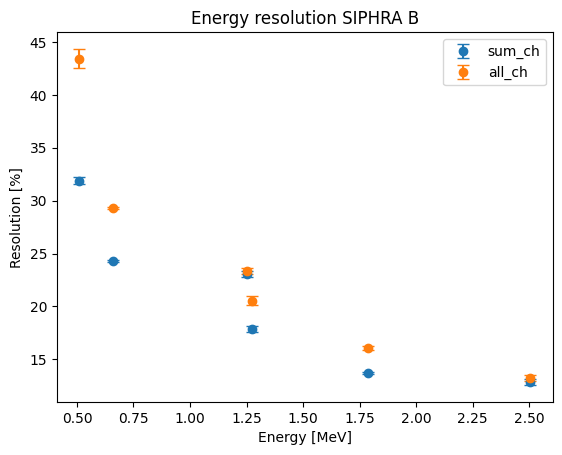

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

siphra = 'B'

def exponential(x, A, B):
    return A * np.exp(B * x)

for i in range(2):

    trigger = triggers[i]

    data = resolutions[siphra][i]
    x, y, y_err = zip(*data)

    # Fit exponential
    popt, pcov = curve_fit(exponential, x, y)
    A, B = popt

    # Scatter data
    plt.errorbar(x, y, yerr=y_err, fmt="o", capsize = 4, label=f"{trigger}")

    # Smooth fitted curve
    #x_fit = np.linspace(min(x), max(x), 200)
    #y_fit = exponential(x_fit, A, B)

    #plt.plot(
    #    x_fit,
    #    y_fit,
    #    label=f"{trigger}"
    #)

    plt.xlabel("Energy [MeV]")
    plt.ylabel("Resolution [%]")
    plt.title(f"Energy resolution SIPHRA {siphra}")

plt.legend()
plt.show()